Start by loading the `tidymodels` package...

In [1]:
library(tidyverse)
library(tidymodels)
library(vip)

set.seed(512)
options(repr.plot.width = 8, repr.plot.height = 5)
theme_set(theme_gray(base_size = 14))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     

── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──


✔ broom        1.0.13     ✔ rsample      1.3.2 
✔ dials        1.4.4      ✔ tailor       0.1.0 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ recipes      1.4.0      ✔ yardstick    1.4.0 


── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ scales::discard() masks purrr::discard()
✖ dplyr::filter()   masks stats::filter()
✖ recipes::fixed()  masks stringr::fixed()
✖ dplyr::lag()      masks stats::lag()
✖ yardstick::spec() masks readr::spec()
✖ recipes::step()   masks stats::step()
• Learn how to get started at https://www.tidymodels.org/start/



Attaching package: ‘vip’



The following object is masked from ‘package:utils’:

    vi



Let's work with [hotel bookings data](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md) from TidyTuesday. 

In [2]:
hotels =
  readr::read_csv("https://tidymodels.org/start/case-study/hotels.csv", col_types = readr::cols()) |>
  mutate(across(where(is.character), as.factor))

hotels |> head()

  hotel        lead_time stays_in_weekend_nights stays_in_week_nights adults
1 City_Hotel   217       1                       3                    2     
2 City_Hotel     2       0                       1                    2     
3 Resort_Hotel  95       2                       5                    2     
4 Resort_Hotel 143       2                       6                    2     
5 Resort_Hotel 136       1                       4                    2     
6 City_Hotel    67       2                       2                    2     
  children meal country market_segment distribution_channel ⋯
1 none     BB   DEU     Offline_TA/TO  TA/TO                ⋯
2 none     BB   PRT     Direct         Direct               ⋯
3 none     BB   GBR     Online_TA      TA/TO                ⋯
4 none     HB   ROU     Online_TA      TA/TO                ⋯
5 none     HB   PRT     Direct         Direct               ⋯
6 none     SC   GBR     Online_TA      TA/TO                ⋯
  reserved_room_type assign

Each row is a "stay" and we want to predict whether the stay included children given the other features.

We'll want to extract a bit more information from the `arrival_date` column. So, let's make a `recipe`.

In [3]:
rec = recipe(children ~ ., data = hotels) |>
    step_date(arrival_date) |>
    step_holiday(arrival_date) |>
    step_rm(arrival_date) |>
    prep()

What does this recipe do? Look at the transformed data with "juice".

In [4]:
hotels_processed = juice(rec)
hotels_processed |> head()

  hotel        lead_time stays_in_weekend_nights stays_in_week_nights adults
1 City_Hotel   217       1                       3                    2     
2 City_Hotel     2       0                       1                    2     
3 Resort_Hotel  95       2                       5                    2     
4 Resort_Hotel 143       2                       6                    2     
5 Resort_Hotel 136       1                       4                    2     
6 City_Hotel    67       2                       2                    2     
  meal country market_segment distribution_channel is_repeated_guest ⋯
1 BB   DEU     Offline_TA/TO  TA/TO                0                 ⋯
2 BB   PRT     Direct         Direct               0                 ⋯
3 BB   GBR     Online_TA      TA/TO                0                 ⋯
4 HB   ROU     Online_TA      TA/TO                0                 ⋯
5 HB   PRT     Direct         Direct               0                 ⋯
6 SC   GBR     Online_TA      TA/TO

The recipe uses `children` as the outcome and all other columns as predictors. `step_date()` extracts weekday, month, and year from `arrival_date`; `step_holiday()` adds holiday indicators; and `step_rm()` removes the original date. `prep()` estimates the preprocessing steps, and `juice()` returns the transformed training data.

Let's start with a decision tree. 

In [5]:
mod = decision_tree() |>
    set_engine('rpart') |>
    set_mode('classification')

Fit `mod` using the data from your prepped recipe. (Hint: remember `juice`).

In [6]:
set.seed(512)
mod_fit = mod |> fit(children ~ ., data = hotels_processed)
mod_fit

parsnip model object

n= 50000 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

 1) root 50000 4038 none (0.08076000 0.91924000)  
   2) reserved_room_type=C,F,G,H 2850 1205 children (0.57719298 0.42280702)  
     4) average_daily_rate>=130.025 1879  581 children (0.69079297 0.30920703)  
       8) market_segment=Groups,Offline_TA/TO,Online_TA 1253  286 children (0.77174781 0.22825219) *
       9) market_segment=Corporate,Direct 626  295 children (0.52875399 0.47124601)  
        18) assigned_room_type=B,C,G,H,K 375  120 children (0.68000000 0.32000000) *
        19) assigned_room_type=A,E,F,I 251   76 none (0.30278884 0.69721116) *
     5) average_daily_rate< 130.025 971  347 none (0.35736354 0.64263646)  
      10) reserved_room_type=C,G,H 554  251 children (0.54693141 0.45306859)  
        20) adults>=1.5 502  201 children (0.59960159 0.40039841) *
        21) adults< 1.5 52    2 none (0.03846154 0.96153846) *
      11) reserved_room_type=F 417   44 none (0.1055

Use the snippet below to visualize the tree. What is the first split?

```r
rpart.plot::rpart.plot(mod_fit$fit)
```

Warning message:
“Cannot retrieve the data used to build the model (so cannot determine roundint and is.binary for the variables).
To silence this warning:
    Call rpart.plot with roundint=FALSE,
    or rebuild the rpart model with model=TRUE.”


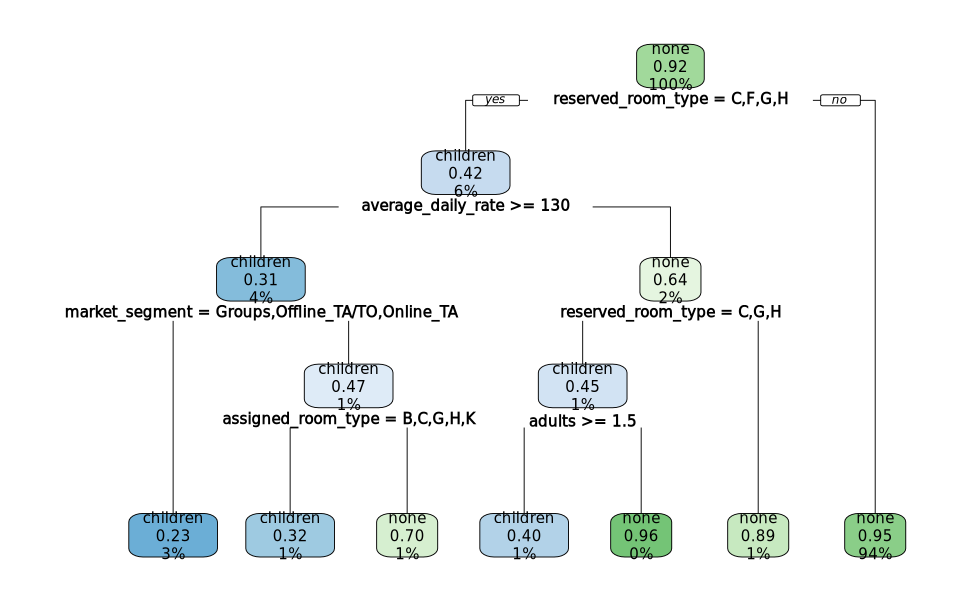

                   count ncat improve  index adj
reserved_room_type 50000 9    1489.651 1     0  

In [7]:
rpart.plot::rpart.plot(mod_fit$fit)


mod_fit$fit$splits[1, , drop = FALSE]

The first split is on `reserved_room_type`: rooms C, F, G, and H go to one branch, while rooms A, B, D, E, and L go to the other. In the training data, about 57.7% of stays in the first group included children, compared with 5.1% in the second group.

Now create a `random_forest` model and fit it to the transformed `hotels` data.

1. the `mode` should be "classification", and,
2. add `importance = "impurity"` to `set_engine` so we can calculate feature importances with the model.

In [8]:
rf_mod = rand_forest(trees = 500) |>
    set_engine("ranger", importance = "impurity", num.threads = 2) |>
    set_mode("classification")

set.seed(512)
rf_fit = rf_mod |> fit(children ~ ., data = hotels_processed)
rf_fit

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, num.trees = 500,      importance = "impurity", num.threads = 2, verbose = FALSE,      seed = sample.int(10^5, 1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  500 
Sample size:                      50000 
Number of independent variables:  27 
Mtry:                             5 
Target node size:                 10 
Variable importance mode:         impurity 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.04210533 

We can plot the feature importances. Pipe your fitted model into `extract_fit_engine()` and then into `vip(num_features = 20)`.

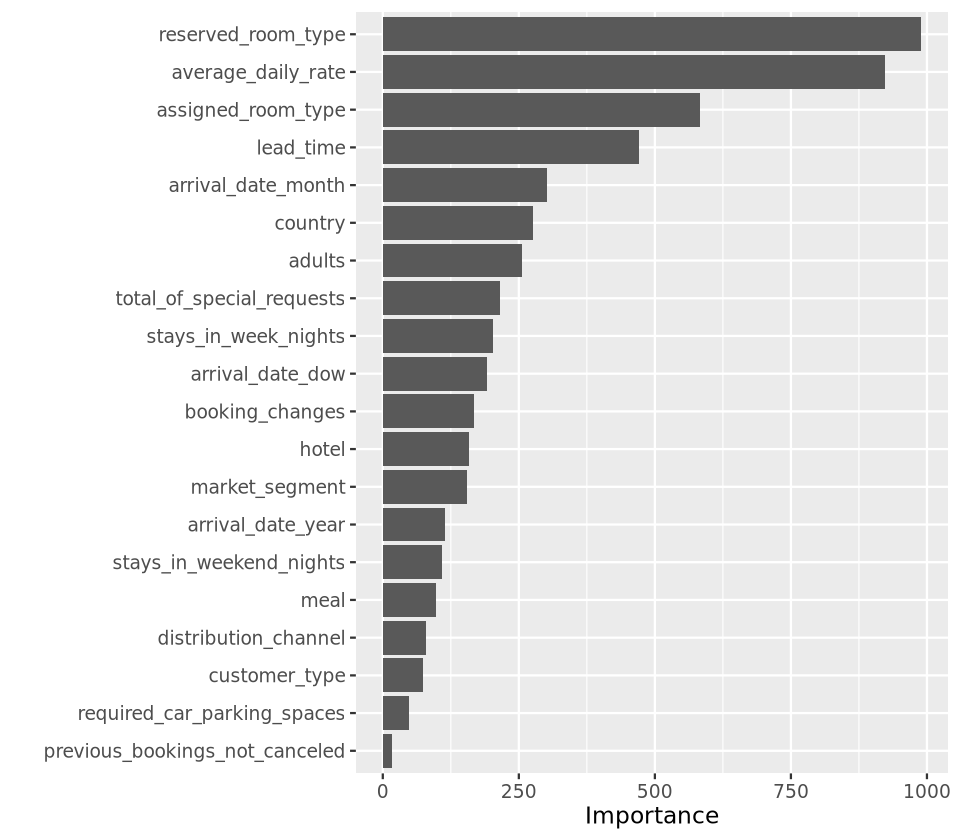

In [9]:
options(repr.plot.width = 8, repr.plot.height = 7)

rf_fit |>
    extract_fit_engine() |>
    vip(num_features = 20)

The random forest predicts whether a stay includes children. The importance plot ranks predictors by their total reduction in node impurity across the trees. These values describe the fitted model, rather than causal effects. As requested in the exercise, both models are fit to the transformed data; no held-out test-set performance is estimated here.